# 02 — Residual Analysis

Analyse backbone residuals to motivate and validate the Kronecker prior structure.
Implemented in Phase 3. Stub only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

RESULTS = Path("../results")
DATA    = Path("../data/processed")
FIGS    = RESULTS / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 150, "font.size": 10})
HORIZONS = np.arange(1, 13)          # 1–12 (5-min steps)
HORIZON_LABELS = [f"h{h}" for h in HORIZONS]


In [2]:
def load_residuals(backbone: str, dataset: str, split: str, seed: int = 0) -> tuple:
    """Load residuals npz; return (residuals, y_pred, y_true, mask) all float32/bool."""
    path = RESULTS / "residuals" / f"{backbone}_{dataset}_{split}_seed{seed}.npz"
    d = np.load(path)
    r = d["residuals"].squeeze(-1)   # (N_win, 12, N)
    y_pred = d["y_pred"].squeeze(-1)
    y_true = d["y_true"].squeeze(-1)
    mask = d["mask"].squeeze(-1).astype(bool)
    return r, y_pred, y_true, mask


def per_horizon_variance(r: np.ndarray, mask: np.ndarray) -> np.ndarray:
    """Empirical Var(R_h) for h=0..11 using only valid readings."""
    var = np.empty(12)
    for h in range(12):
        vals = r[:, h, :][mask[:, h, :]]
        var[h] = float(vals.var())
    return var


def temporal_covariance(r: np.ndarray, mask: np.ndarray) -> np.ndarray:
    """12×12 temporal covariance averaged over all (window, sensor) pairs."""
    # r: (N_win, 12, N)  ->  flatten to (N_win*N, 12) then pairwise
    r_f = r.transpose(0, 2, 1).reshape(-1, 12)      # (M, 12)
    m_f = mask.transpose(0, 2, 1).reshape(-1, 12)   # (M, 12)
    r_f = r_f * m_f
    num   = r_f.T @ r_f                              # (12, 12)
    denom = m_f.T @ m_f                              # (12, 12)
    return num / np.maximum(denom, 1)


def spatial_covariance(r: np.ndarray, mask: np.ndarray) -> np.ndarray:
    """N×N spatial covariance averaged across all horizons and windows."""
    N = r.shape[2]
    num   = np.zeros((N, N))
    denom = np.zeros((N, N))
    for h in range(12):
        r_h = r[:, h, :] * mask[:, h, :]   # (N_win, N)
        m_h = mask[:, h, :].astype(float)
        num   += r_h.T @ r_h
        denom += m_h.T @ m_h
    return num / np.maximum(denom, 1)


def separability_error(r: np.ndarray, mask: np.ndarray,
                       Q: np.ndarray, sig_S: np.ndarray,
                       n_sensors: int = 30, seed: int = 42) -> float:
    """Relative Frobenius error of best-scaled Kronecker approx on a sensor subset."""
    rng = np.random.default_rng(seed)
    N = r.shape[2]
    idx = rng.choice(N, n_sensors, replace=False)

    r_sub = r[:, :, idx].reshape(r.shape[0], -1)   # (N_win, 12*S)
    m_sub = mask[:, :, idx].all(axis=(1, 2))        # (N_win,) windows fully valid
    r_valid = r_sub[m_sub]

    Sigma_full = np.cov(r_valid.T)                  # (12*S, 12*S)
    Sigma_kron = np.kron(Q, sig_S[np.ix_(idx, idx)])

    # Best scalar scaling
    f = Sigma_full.ravel()
    k = Sigma_kron.ravel()
    c = float(f @ k) / float(k @ k + 1e-12)
    diff = np.linalg.norm(Sigma_full - c * Sigma_kron, "fro")
    return float(diff / (np.linalg.norm(Sigma_full, "fro") + 1e-12))


def spectral_projection(sig_S: np.ndarray, eigvecs: np.ndarray) -> np.ndarray:
    """diag(U^T Σ_S U) — energy in each Laplacian eigenmode."""
    proj = eigvecs.T @ sig_S @ eigvecs
    return np.diag(proj)


## METR-LA — GWN backbone

In [3]:
BACKBONE = "gwn"
DATASET  = "metrla"

r_tr, _, _, m_tr = load_residuals(BACKBONE, DATASET, "train")
r_te, _, _, m_te = load_residuals(BACKBONE, DATASET, "test")

eigs_data = np.load(DATA / "metrla_laplacian_eigs.npz")
eigvals   = eigs_data["eigenvalues"]   # (207,)
eigvecs   = eigs_data["eigenvectors"]  # (207, 207)  columns = eigenvectors

print(f"Train residuals: {r_tr.shape}  valid={m_tr.mean():.3f}")
print(f"Test  residuals: {r_te.shape}  valid={m_te.mean():.3f}")


Train residuals: (23967, 12, 207)  valid=0.929
Test  residuals: (6831, 12, 207)  valid=0.879


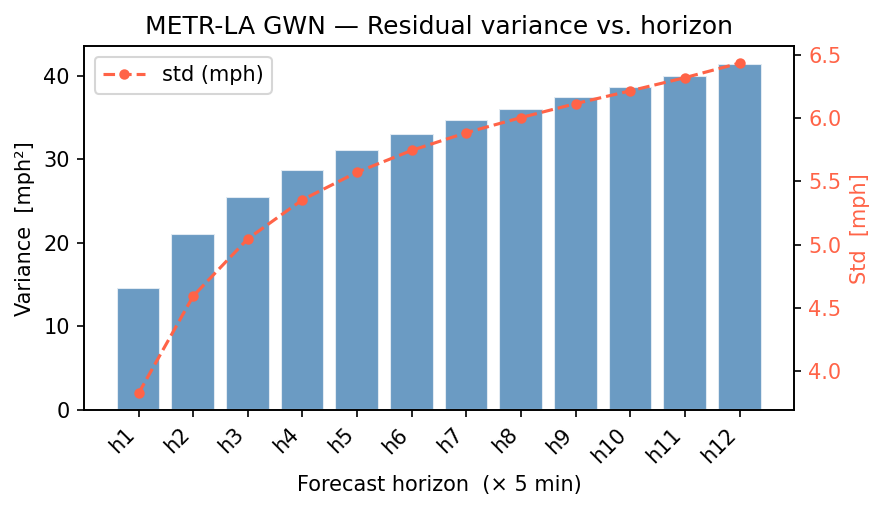

Monotone growth: ✓ PASS
Per-horizon std: h1=3.82  h2=4.59  h3=5.05  h4=5.36  h5=5.57  h6=5.75  h7=5.89  h8=6.01  h9=6.12  h10=6.22  h11=6.32  h12=6.44


In [4]:
# ── fig_variance_vs_horizon ────────────────────────────────────────────────
var_h = per_horizon_variance(r_tr, m_tr)
std_h = np.sqrt(var_h)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(HORIZONS, var_h, color="steelblue", alpha=0.8, edgecolor="white")
ax.set_xlabel("Forecast horizon  (× 5 min)")
ax.set_ylabel("Variance  [mph²]")
ax.set_title("METR-LA GWN — Residual variance vs. horizon")
ax.set_xticks(HORIZONS)
ax.set_xticklabels(HORIZON_LABELS, rotation=45, ha="right")
ax2 = ax.twinx()
ax2.plot(HORIZONS, std_h, "o--", color="tomato", lw=1.5, ms=4, label="std (mph)")
ax2.set_ylabel("Std  [mph]", color="tomato")
ax2.tick_params(axis="y", labelcolor="tomato")
ax2.legend(loc="upper left")
plt.tight_layout()
fig.savefig(FIGS / "fig_variance_vs_horizon.png", dpi=150)
plt.show()

# Go/no-go: variance must grow monotonically
mono = all(var_h[i] <= var_h[i+1] for i in range(11))
print(f"Monotone growth: {'✓ PASS' if mono else '✗ FAIL'}")
print("Per-horizon std:", "  ".join(f"h{h+1}={s:.2f}" for h, s in enumerate(std_h)))


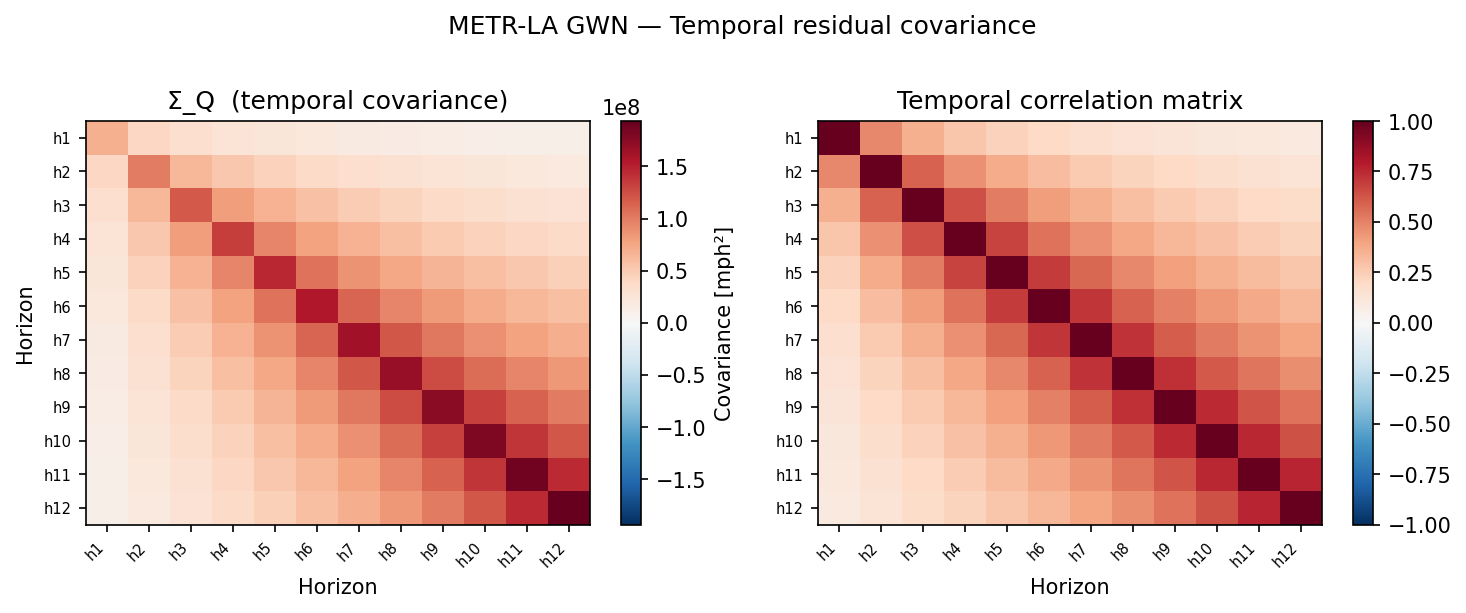

Lag-1 autocorrelation per horizon: ρ(1,2)=0.484  ρ(2,3)=0.592  ρ(3,4)=0.644  ρ(4,5)=0.676  ρ(5,6)=0.697  ρ(6,7)=0.713  ρ(7,8)=0.724  ρ(8,9)=0.733  ρ(9,10)=0.743  ρ(10,11)=0.751  ρ(11,12)=0.759


In [5]:
# ── fig_sigma_Q — temporal covariance heatmap ──────────────────────────────
Q = temporal_covariance(r_tr, m_tr)   # (12, 12)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

im = axes[0].imshow(Q, cmap="RdBu_r", aspect="auto",
                    vmin=-np.abs(Q).max(), vmax=np.abs(Q).max())
axes[0].set_title("Σ_Q  (temporal covariance)")
axes[0].set_xlabel("Horizon"); axes[0].set_ylabel("Horizon")
axes[0].set_xticks(range(12)); axes[0].set_yticks(range(12))
axes[0].set_xticklabels(HORIZON_LABELS, rotation=45, ha="right", fontsize=7)
axes[0].set_yticklabels(HORIZON_LABELS, fontsize=7)
plt.colorbar(im, ax=axes[0], label="Covariance [mph²]")

# Normalised correlation matrix
d_inv = 1.0 / np.sqrt(np.diag(Q).clip(1e-8))
Q_corr = d_inv[:, None] * Q * d_inv[None, :]
im2 = axes[1].imshow(Q_corr, cmap="RdBu_r", aspect="auto", vmin=-1, vmax=1)
axes[1].set_title("Temporal correlation matrix")
axes[1].set_xlabel("Horizon")
axes[1].set_xticks(range(12)); axes[1].set_yticks(range(12))
axes[1].set_xticklabels(HORIZON_LABELS, rotation=45, ha="right", fontsize=7)
axes[1].set_yticklabels(HORIZON_LABELS, fontsize=7)
plt.colorbar(im2, ax=axes[1])

plt.suptitle("METR-LA GWN — Temporal residual covariance", y=1.01)
plt.tight_layout()
fig.savefig(FIGS / "fig_sigma_Q.png", dpi=150, bbox_inches="tight")
plt.show()

# Check lag-1 autocorrelation as a function of horizon
lags = [Q_corr[h, h+1] for h in range(11)]
print("Lag-1 autocorrelation per horizon:", "  ".join(f"ρ({h+1},{h+2})={v:.3f}" for h, v in enumerate(lags)))


Computing spatial covariance (may take ~30 s)...


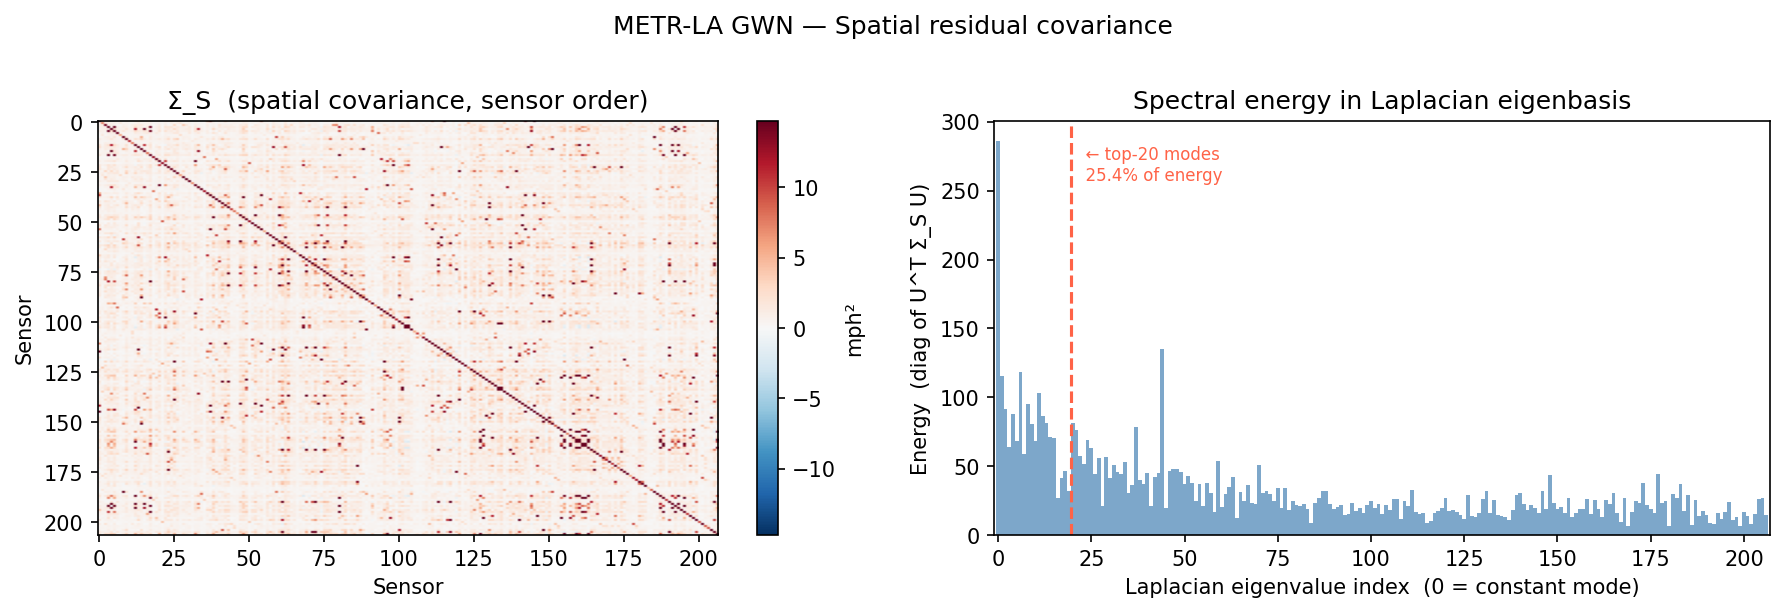

Top-20 Laplacian modes capture 25.4% of spatial variance energy


In [6]:
# ── fig_sigma_R_spectral — spatial covariance in Laplacian eigenbasis ───────
print("Computing spatial covariance (may take ~30 s)...")
sig_S = spatial_covariance(r_tr, m_tr)   # (207, 207)
spec  = spectral_projection(sig_S, eigvecs)  # (207,) energy per eigenmode

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: full Sigma_S heatmap (sorted by sensor index)
lim = np.percentile(np.abs(sig_S), 99)
im = axes[0].imshow(sig_S, cmap="RdBu_r", aspect="auto", vmin=-lim, vmax=lim)
axes[0].set_title("Σ_S  (spatial covariance, sensor order)")
axes[0].set_xlabel("Sensor"); axes[0].set_ylabel("Sensor")
plt.colorbar(im, ax=axes[0], label="mph²")

# Right: spectral energy vs eigenvalue index
axes[1].bar(np.arange(len(spec)), spec, width=1.0, color="steelblue", alpha=0.7)
axes[1].set_xlabel("Laplacian eigenvalue index  (0 = constant mode)")
axes[1].set_ylabel("Energy  (diag of U^T Σ_S U)")
axes[1].set_title("Spectral energy in Laplacian eigenbasis")
axes[1].set_xlim(-1, len(spec))

# Annotate low-frequency fraction
low_freq_frac = spec[:20].sum() / spec.sum()
axes[1].axvline(19.5, color="tomato", ls="--", lw=1.5)
axes[1].text(20.5, spec.max() * 0.9, f"  ← top-20 modes\n  {low_freq_frac:.1%} of energy",
             color="tomato", fontsize=8)

plt.suptitle("METR-LA GWN — Spatial residual covariance", y=1.01)
plt.tight_layout()
fig.savefig(FIGS / "fig_sigma_R_spectral.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Top-20 Laplacian modes capture {low_freq_frac:.1%} of spatial variance energy")


In [7]:
# ── Separability Frobenius error ────────────────────────────────────────────
print("Computing separability error (sensor subset, may take ~20 s)...")
sep_err = separability_error(r_tr, m_tr, Q, sig_S, n_sensors=30)

print(f"\nSeparability Frobenius relative error: {sep_err:.3f}  ({sep_err*100:.1f}%)")
if sep_err < 0.40:
    print("✓ PASS — Kronecker approximation defensible (<40%)")
else:
    print("✗ WARNING — Error ≥40%; document as limitation before proceeding")


Computing separability error (sensor subset, may take ~20 s)...



Separability Frobenius relative error: 0.262  (26.2%)
✓ PASS — Kronecker approximation defensible (<40%)


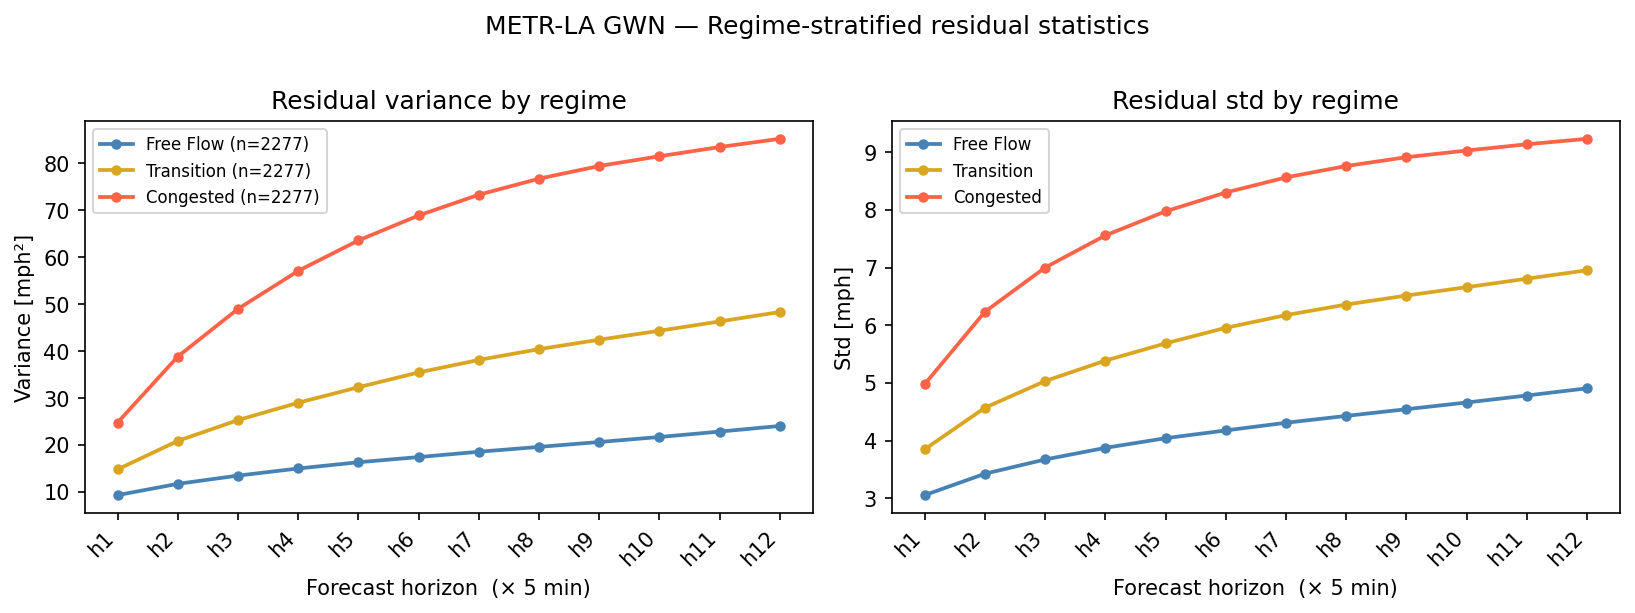

free_flow   : h12 std = 4.90 mph
transition  : h12 std = 6.95 mph
congested   : h12 std = 9.23 mph


In [8]:
# ── fig_variance_by_regime ──────────────────────────────────────────────────
regimes_data = np.load(DATA / "metrla_regimes_test.npz")
regime_labels = regimes_data["regime"]          # (6831,) str array
unique_regimes = ["free_flow", "transition", "congested"]
colors = {"free_flow": "steelblue", "transition": "goldenrod", "congested": "tomato"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for regime in unique_regimes:
    idx = np.where(regime_labels == regime)[0]
    r_reg = r_te[idx]       # (n_regime, 12, N)
    m_reg = m_te[idx]
    var_regime = per_horizon_variance(r_reg, m_reg)
    std_regime = np.sqrt(var_regime)
    label = regime.replace("_", " ").title()

    axes[0].plot(HORIZONS, var_regime, "o-", color=colors[regime],
                 label=f"{label} (n={len(idx)})", lw=1.8, ms=4)
    axes[1].plot(HORIZONS, std_regime, "o-", color=colors[regime],
                 label=f"{label}", lw=1.8, ms=4)

for ax, ylabel, title in zip(
    axes,
    ["Variance [mph²]", "Std [mph]"],
    ["Residual variance by regime", "Residual std by regime"]
):
    ax.set_xlabel("Forecast horizon  (× 5 min)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks(HORIZONS)
    ax.set_xticklabels(HORIZON_LABELS, rotation=45, ha="right")
    ax.legend(fontsize=8)

plt.suptitle("METR-LA GWN — Regime-stratified residual statistics", y=1.01)
plt.tight_layout()
fig.savefig(FIGS / "fig_variance_by_regime.png", dpi=150, bbox_inches="tight")
plt.show()

for regime in unique_regimes:
    idx = np.where(regime_labels == regime)[0]
    r_reg = r_te[idx]; m_reg = m_te[idx]
    std_h12 = float(r_reg[:, 11, :][m_reg[:, 11, :]].std())
    print(f"{regime:12s}: h12 std = {std_h12:.2f} mph")


## PEMS-BAY — GWN backbone

In [9]:
BACKBONE2 = "gwn"
DATASET2  = "pemsbay"

r_tr2, _, _, m_tr2 = load_residuals(BACKBONE2, DATASET2, "train")

# Test split may still be extracting — skip regime figure if not ready yet
_test_path = RESULTS / "residuals" / f"{BACKBONE2}_{DATASET2}_test_seed0.npz"
if _test_path.exists():
    r_te2, _, _, m_te2 = load_residuals(BACKBONE2, DATASET2, "test")
    _have_test2 = True
else:
    print("⚠ PEMS-BAY test residuals not yet extracted — regime figure will be skipped.")
    r_te2 = m_te2 = None
    _have_test2 = False

eigs2     = np.load(DATA / "pemsbay_laplacian_eigs.npz")
eigvals2  = eigs2["eigenvalues"]   # (325,)
eigvecs2  = eigs2["eigenvectors"]  # (325, 325)

regimes2_data  = np.load(DATA / "pemsbay_regimes_test.npz")
regime_labels2 = regimes2_data["regime"]

print(f"Train residuals: {r_tr2.shape}  valid={m_tr2.mean():.3f}")
if _have_test2:
    print(f"Test  residuals: {r_te2.shape}  valid={m_te2.mean():.3f}")


Train residuals: (36458, 12, 325)  valid=1.000
Test  residuals: (10400, 12, 325)  valid=1.000


Computing PEMS-BAY spatial covariance (may take ~60 s)...


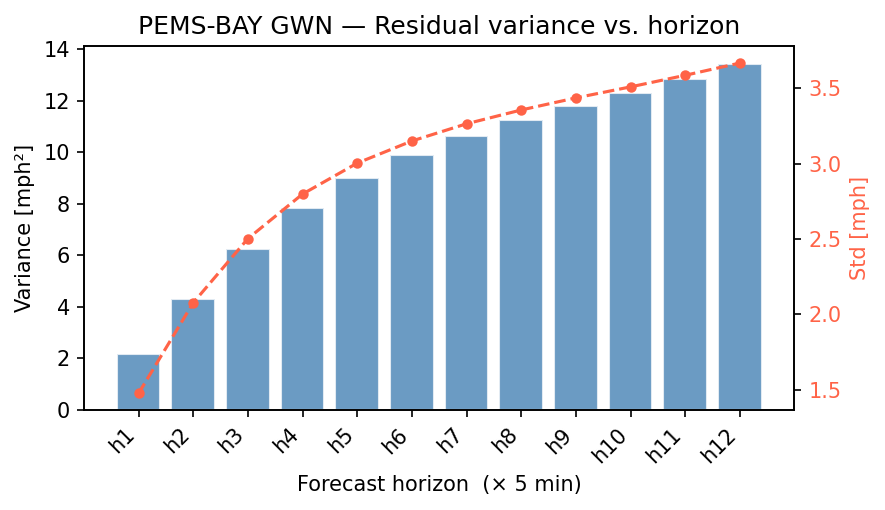

Monotone growth: ✓ PASS


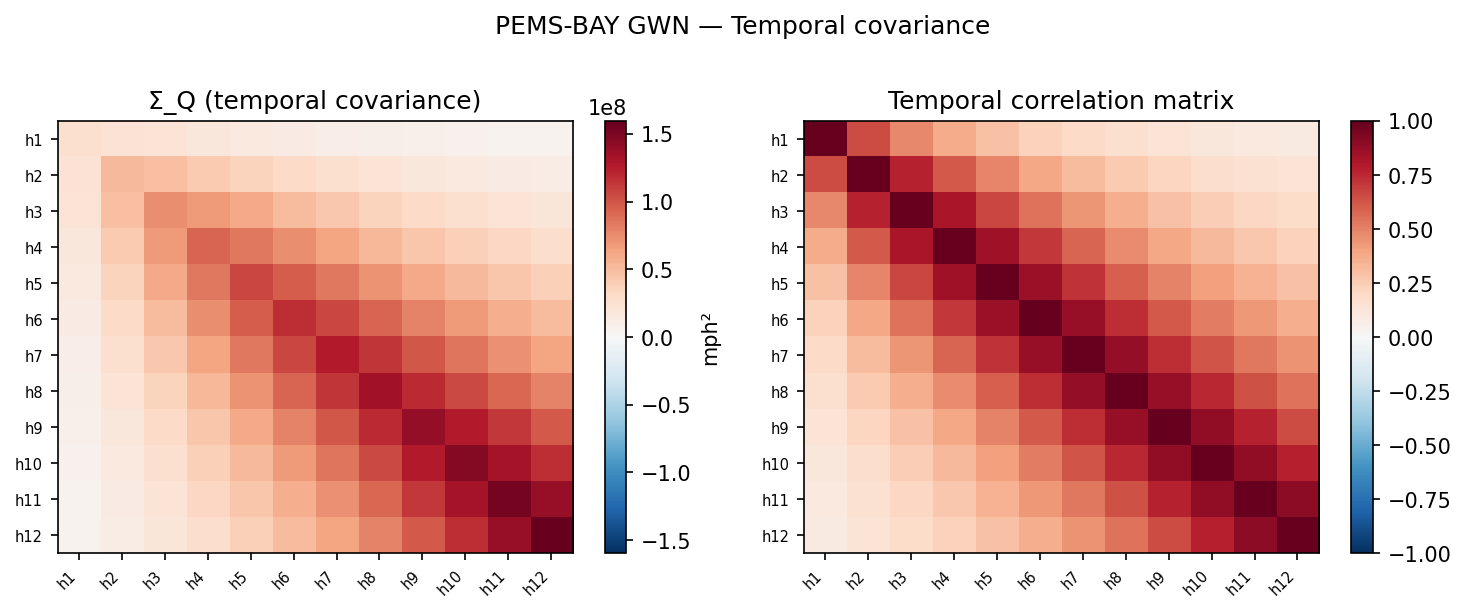

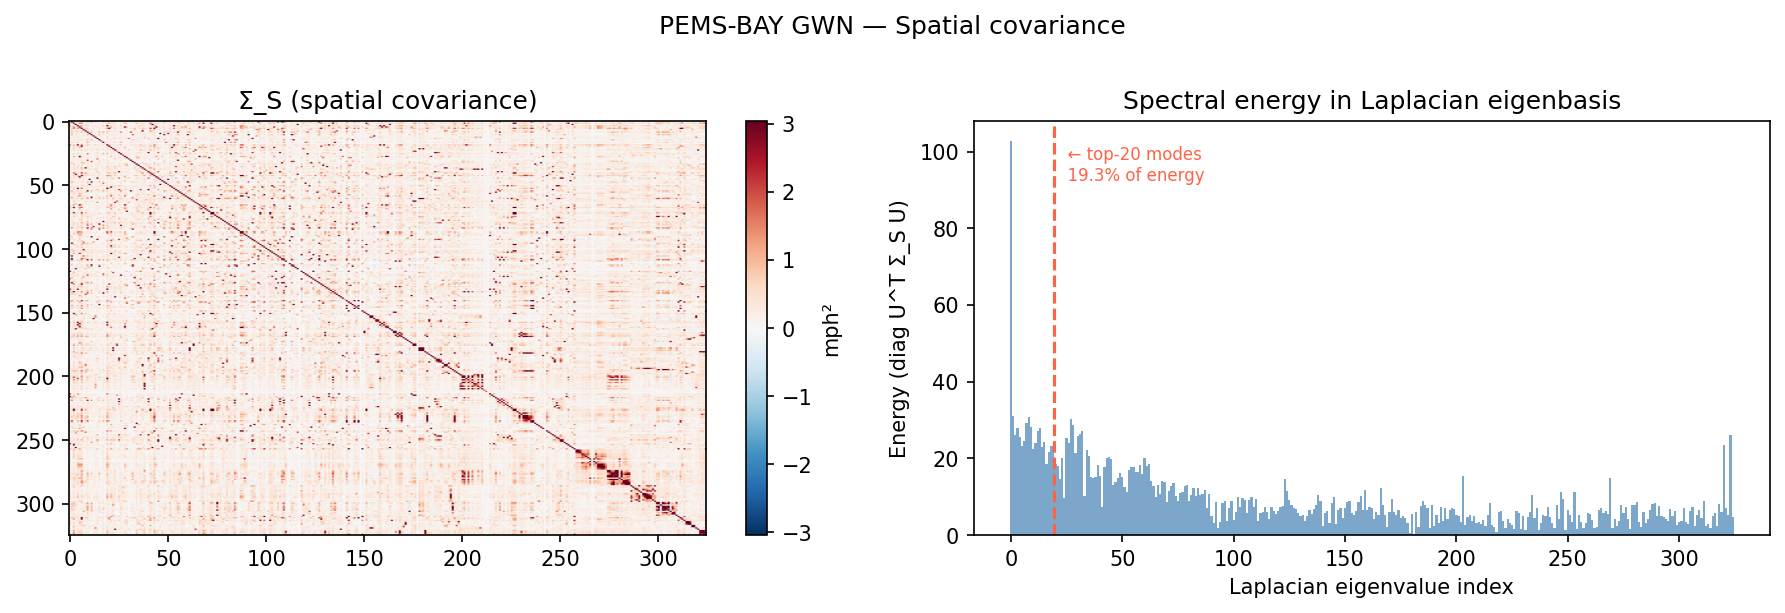

Top-20 modes: 19.3% of spatial energy


PEMS-BAY separability error: 0.125 (12.5%)  ✓ PASS


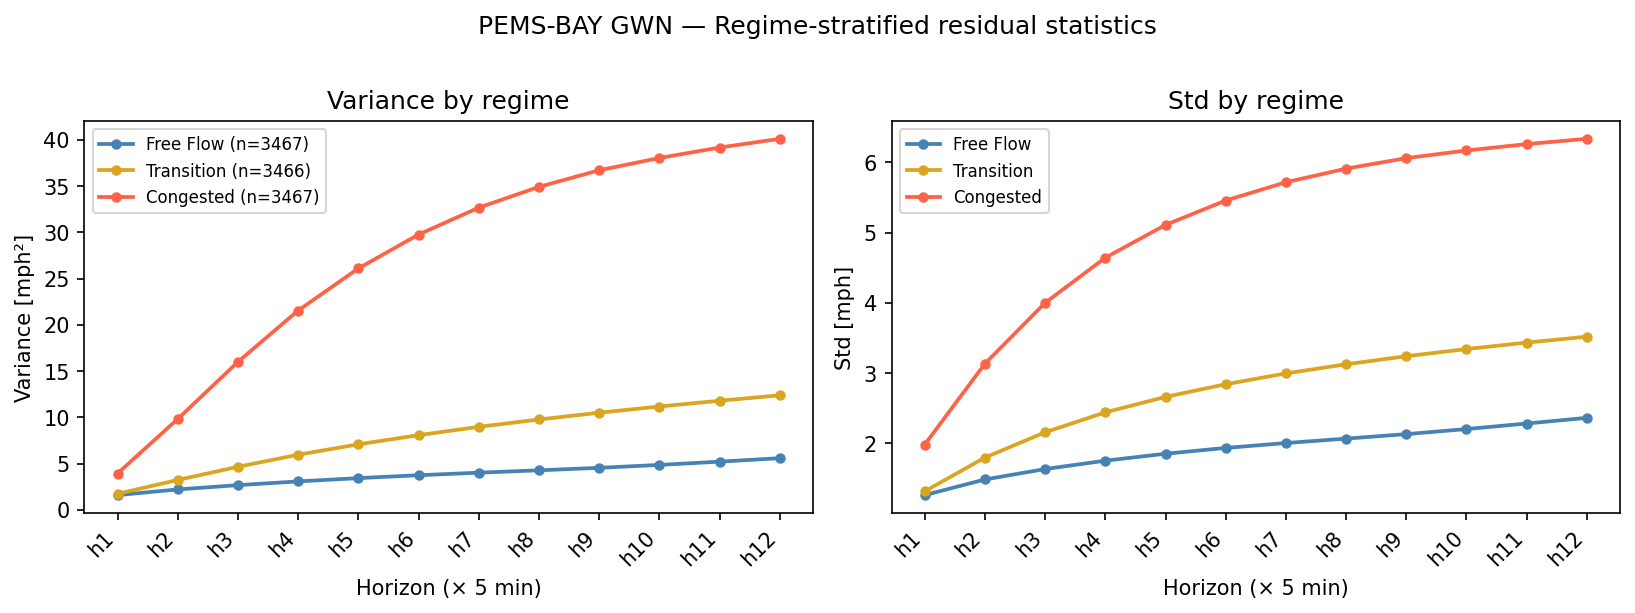

In [10]:
# All four figures for PEMS-BAY in one cell
var_h2 = per_horizon_variance(r_tr2, m_tr2)
Q2     = temporal_covariance(r_tr2, m_tr2)
print("Computing PEMS-BAY spatial covariance (may take ~60 s)...")
sig_S2 = spatial_covariance(r_tr2, m_tr2)
spec2  = spectral_projection(sig_S2, eigvecs2)

# ── variance vs horizon ──
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(HORIZONS, var_h2, color="steelblue", alpha=0.8, edgecolor="white")
ax.set_xlabel("Forecast horizon  (× 5 min)"); ax.set_ylabel("Variance [mph²]")
ax.set_title("PEMS-BAY GWN — Residual variance vs. horizon")
ax.set_xticks(HORIZONS); ax.set_xticklabels(HORIZON_LABELS, rotation=45, ha="right")
ax2 = ax.twinx()
ax2.plot(HORIZONS, np.sqrt(var_h2), "o--", color="tomato", lw=1.5, ms=4)
ax2.set_ylabel("Std [mph]", color="tomato"); ax2.tick_params(axis="y", labelcolor="tomato")
plt.tight_layout()
fig.savefig(FIGS / "fig_variance_vs_horizon_pemsbay.png", dpi=150); plt.show()

mono2 = all(var_h2[i] <= var_h2[i+1] for i in range(11))
print(f"Monotone growth: {'✓ PASS' if mono2 else '✗ FAIL'}")

# ── temporal covariance ──
d_inv2 = 1.0 / np.sqrt(np.diag(Q2).clip(1e-8))
Q2_corr = d_inv2[:, None] * Q2 * d_inv2[None, :]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
im = axes[0].imshow(Q2, cmap="RdBu_r", aspect="auto",
                    vmin=-np.abs(Q2).max(), vmax=np.abs(Q2).max())
axes[0].set_title("Σ_Q (temporal covariance)"); plt.colorbar(im, ax=axes[0], label="mph²")
axes[0].set_xticks(range(12)); axes[0].set_xticklabels(HORIZON_LABELS, rotation=45, ha="right", fontsize=7)
axes[0].set_yticks(range(12)); axes[0].set_yticklabels(HORIZON_LABELS, fontsize=7)
im2 = axes[1].imshow(Q2_corr, cmap="RdBu_r", aspect="auto", vmin=-1, vmax=1)
axes[1].set_title("Temporal correlation matrix"); plt.colorbar(im2, ax=axes[1])
axes[1].set_xticks(range(12)); axes[1].set_xticklabels(HORIZON_LABELS, rotation=45, ha="right", fontsize=7)
axes[1].set_yticks(range(12)); axes[1].set_yticklabels(HORIZON_LABELS, fontsize=7)
plt.suptitle("PEMS-BAY GWN — Temporal covariance", y=1.01); plt.tight_layout()
fig.savefig(FIGS / "fig_sigma_Q_pemsbay.png", dpi=150, bbox_inches="tight"); plt.show()

# ── spectral ──
lf2 = spec2[:20].sum() / spec2.sum()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
lim2 = np.percentile(np.abs(sig_S2), 99)
im = axes[0].imshow(sig_S2, cmap="RdBu_r", aspect="auto", vmin=-lim2, vmax=lim2)
axes[0].set_title("Σ_S (spatial covariance)"); plt.colorbar(im, ax=axes[0], label="mph²")
axes[1].bar(np.arange(len(spec2)), spec2, width=1.0, color="steelblue", alpha=0.7)
axes[1].axvline(19.5, color="tomato", ls="--", lw=1.5)
axes[1].text(20.5, spec2.max() * 0.9, f"  ← top-20 modes\n  {lf2:.1%} of energy", color="tomato", fontsize=8)
axes[1].set_xlabel("Laplacian eigenvalue index"); axes[1].set_ylabel("Energy (diag U^T Σ_S U)")
axes[1].set_title("Spectral energy in Laplacian eigenbasis")
plt.suptitle("PEMS-BAY GWN — Spatial covariance", y=1.01); plt.tight_layout()
fig.savefig(FIGS / "fig_sigma_R_spectral_pemsbay.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Top-20 modes: {lf2:.1%} of spatial energy")

# ── separability ──
sep2 = separability_error(r_tr2, m_tr2, Q2, sig_S2, n_sensors=30)
print(f"PEMS-BAY separability error: {sep2:.3f} ({sep2*100:.1f}%)  {'✓ PASS' if sep2 < 0.40 else '✗ WARNING'}")

# ── variance by regime (requires test split) ──
if _have_test2:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for regime in unique_regimes:
        idx2 = np.where(regime_labels2 == regime)[0]
        if len(idx2) == 0:
            continue
        r_reg2 = r_te2[idx2]; m_reg2 = m_te2[idx2]
        var2 = per_horizon_variance(r_reg2, m_reg2)
        label = regime.replace("_", " ").title()
        axes[0].plot(HORIZONS, var2, "o-", color=colors[regime], label=f"{label} (n={len(idx2)})", lw=1.8, ms=4)
        axes[1].plot(HORIZONS, np.sqrt(var2), "o-", color=colors[regime], label=label, lw=1.8, ms=4)
    for ax, yl, tl in zip(axes, ["Variance [mph²]", "Std [mph]"], ["Variance by regime", "Std by regime"]):
        ax.set_xlabel("Horizon (× 5 min)"); ax.set_ylabel(yl); ax.set_title(tl)
        ax.set_xticks(HORIZONS); ax.set_xticklabels(HORIZON_LABELS, rotation=45, ha="right"); ax.legend(fontsize=8)
    plt.suptitle("PEMS-BAY GWN — Regime-stratified residual statistics", y=1.01); plt.tight_layout()
    fig.savefig(FIGS / "fig_variance_by_regime_pemsbay.png", dpi=150, bbox_inches="tight"); plt.show()
else:
    print("Skipping regime figure — re-run this cell once gwn_pemsbay_test_seed0.npz is extracted.")
